In [1]:
import pandas as pd
import xgboost as xgb
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

# 1. CHARGEMENT DES DONNÉES (INGESTION)

In [2]:
# Je charge mes 4 fichiers CSV locaux dans des "DataFrames"
customers = pd.read_csv("../data/customers.csv")
contracts = pd.read_csv("../data/contracts.csv")
departements = pd.read_csv("../data/departements.csv")
historical = pd.read_csv("../data/historical.csv")
newclaims = pd.read_csv("../data/newclaims.csv")

# 2. EXPLORATION DES DONNÉES (EDA) POUR TOUS LES FICHIERS

In [3]:
#  Je regroupe tous mes tableaux dans un dictionnaire pour les analyser un par un automatiquement
mes_fichiers = {
    "CLIENTS (Customers)": customers,
    "CONTRATS (Contracts)": contracts,
    "DÉPARTEMENTS (Departements)": departements,
    "HISTORIQUE (Historical)": historical
}

# Je crée une boucle qui va répéter l'exploration complète pour chaque fichier
for nom_fichier, tableau in mes_fichiers.items():

    print(f"\n\n==========================================================")
    print(f"EXPLORATION DU FICHIER : {nom_fichier}")
    print(f"==========================================================")

    print("\n▶ 1. DIMENSIONS (Lignes, Colonnes) :")
    # J'affiche la taille du tableau (nombre de lignes et de colonnes)
    print(tableau.shape)

    print("\n▶ 2. RÉSUMÉ TECHNIQUE :")
    # J'affiche le résumé technique (valeurs nulles et types de données)
    tableau.info()

    print("\n▶ 3. LES 5 PREMIÈRES LIGNES :")
    # J'affiche les 5 premières lignes pour vérifier que le chargement a fonctionné
    print(tableau.head())

    print("\n▶ 4. LES 5 DERNIÈRES LIGNES :")
    # J'affiche les 5 dernières lignes du tableau
    print(tableau.tail())

    print("\n▶ 5. NOMS DES COLONNES :")
    # J'affiche la liste exacte des noms de colonnes
    print(tableau.columns)

    print("\n▶ 6. INDEX :")
    # J'affiche les index (numéros de lignes)
    print(tableau.index)

    print("\n▶ 7. TYPES DE DONNÉES :")
    # J'affiche le type de chaque variable (texte, entier, décimal)
    print(tableau.dtypes)

    print("\n▶ 8. RÉSUMÉ STATISTIQUE :")
    # Je génère un résumé statistique complet (moyenne, min, max) de toutes les colonnes
    print(tableau.describe(include='all'))



EXPLORATION DU FICHIER : CLIENTS (Customers)

▶ 1. DIMENSIONS (Lignes, Colonnes) :
(999, 8)

▶ 2. RÉSUMÉ TECHNIQUE :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   customer_id         999 non-null    object
 1   customer_birthdate  999 non-null    object
 2   customer_group      996 non-null    object
 3   firstname           930 non-null    object
 4   lastname            999 non-null    object
 5   email               800 non-null    object
 6   gender              954 non-null    object
 7   customer_category   968 non-null    object
dtypes: object(8)
memory usage: 62.6+ KB

▶ 3. LES 5 PREMIÈRES LIGNES :
    customer_id customer_birthdate customer_group firstname  lastname  \
0  0-0010009814            8/16/90              D  philippe    ROSSET   
1  0-0010213191            12/5/03              B       NaN     BARIL   
2  0-0

# Étape 3 : Feature Engineering
Création de deux variables dérivées : la durée du contrat et l'âge du
client. Un bug de format de date a été détecté et corrigé à cette étape.

In [4]:
# 2. Durée du contrat (nombre de jours entre début et fin)
contracts['contract_start_date'] = pd.to_datetime(contracts["contract_start_date"])
contracts['contract_end_date'] = pd.to_datetime(contracts["contract_end_date"])
contracts["contract_duration_days"] = (contracts["contract_end_date"] - contracts["contract_start_date"]).dt.days

# 3. Âge du client
customers['customer_birthdate'] = pd.to_datetime(customers['customer_birthdate'], format='%m/%d/%y')

# CORRECTIF OBLIGATOIRE : pandas interprète "68" comme 2068, pas 1968 !
mask_futur = customers['customer_birthdate'] > pd.Timestamp.now()
print(f"Dates de naissance dans le futur détectées : {mask_futur.sum()}")  # → 512
customers.loc[mask_futur, 'customer_birthdate'] -= pd.DateOffset(years=100)

customers['customer_age'] = ((pd.Timestamp.now() - customers['customer_birthdate']).dt.days // 365).astype(int)
print(customers['customer_age'].describe())

Dates de naissance dans le futur détectées : 512
count    999.000000
mean      56.231231
std       16.453480
min       10.000000
25%       46.000000
50%       58.000000
75%       68.000000
max       94.000000
Name: customer_age, dtype: float64


# Étape 4 : Conformité RGPD (Privacy by Design)
Suppression de tout identifiant personnel direct avant toute fusion,
conformément au principe de minimisation des données.

In [5]:
customers_clean = customers.drop(columns=["customer_birthdate", "firstname", "lastname", "email"], errors='ignore')
contracts_clean = contracts.drop(columns=["car_model", "car_number", "agency_id", "contract_start_date", "contract_end_date", "product_id"], errors='ignore')
departements_clean = departements.drop(columns=["department", "region"], errors='ignore')
historical_clean = historical.drop(columns=["claim_id", "litigation_flag", "claim_date"], errors='ignore')

# Étape 5 : Fusion (construction du Data Warehouse)
Jointure des 4 tables nettoyées sur leurs clés communes.

In [6]:
cc = contracts_clean.merge(customers_clean, on='customer_id')
cch = cc.merge(historical_clean, on='contract_id')
df_final = cch.merge(departements_clean, on='code_dep')
df_final = df_final.drop(columns=["contract_id", "customer_id"], errors='ignore')

print(f"Shape finale : {df_final.shape}")  # → (1497, 14)
print(f"Colonnes : {list(df_final.columns)}")

Shape finale : (1497, 14)
Colonnes : ['car_brand', 'policies_last_year', 'policies_last_3_years', 'contract_duration_days', 'customer_group', 'gender', 'customer_category', 'customer_age', 'claim_amount', 'expert', 'fraud', 'code_dep', 'latitude', 'longitude']


# Étape 6 : Split stratifié + Pipeline de prétraitement
Séparation Train/Test avant tout entraînement, avec un pipeline
encapsulant standardisation et encodage.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

X = df_final.drop(columns=["fraud"])
Y = df_final["fraud"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify=Y)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Fraude train: {Y_train.mean() * 100:.2f}% / Fraude test: {Y_test.mean() * 100:.2f}%")

numeric_features = ["policies_last_year", "policies_last_3_years", "contract_duration_days",
                    "claim_amount", "code_dep", "latitude", "longitude", "customer_age"]
categorical_features = ["car_brand", "customer_group", "gender", "customer_category", "expert"]

numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features), ("cat", categorical_transformer, categorical_features)])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

Train: (1197, 13), Test: (300, 13)
Fraude train: 3.17% / Fraude test: 3.33%


/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


# Étape 7 : EDA — Visualisations
Exploration visuelle du déséquilibre de classe et du lien entre
montant du sinistre et fraude, avec des graphiques en barres simples
(privilégiés ici à des boxplots, plus difficiles à lire pour un public
non-technique).

/var/folders/d2/2h9xzbcd25x76wt_vzczswgm0000gn/T/ipykernel_52011/236799274.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_final, x="fraud", palette="Set2")


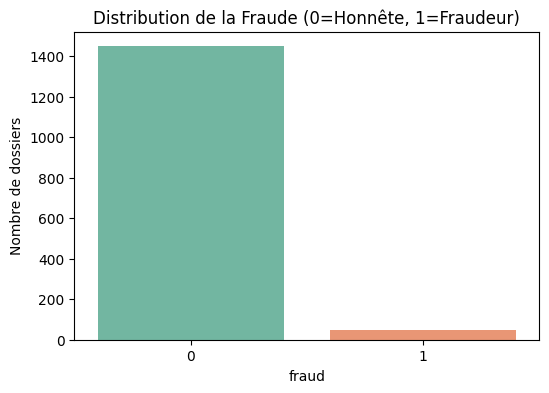

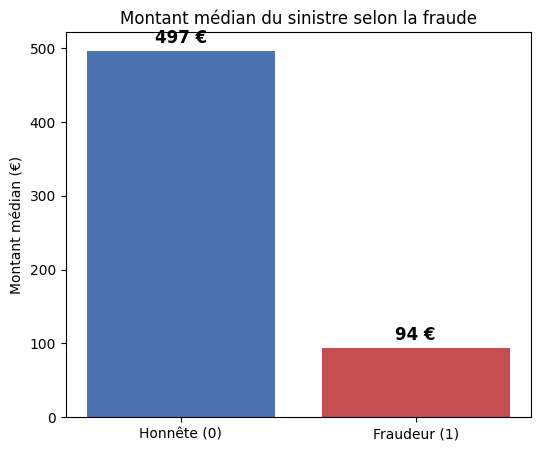

In [8]:
# Graphique 1 : Distribution de la fraude
plt.figure(figsize=(6, 4))
sns.countplot(data=df_final, x="fraud", palette="Set2")
plt.title("Distribution de la Fraude (0=Honnête, 1=Fraudeur)")
plt.ylabel("Nombre de dossiers")
plt.show()

# Graphique 2 : Montant MÉDIAN du sinistre selon la fraude (barres simples)
medianes = df_final.groupby('fraud')['claim_amount'].median()
plt.figure(figsize=(6, 5))
bars = plt.bar(['Honnête (0)', 'Fraudeur (1)'], [medianes[0], medianes[1]], color=['#4C72B0', '#C44E52'])
plt.title("Montant médian du sinistre selon la fraude")
plt.ylabel("Montant médian (€)")
for bar, val in zip(bars, [medianes[0], medianes[1]]):
    plt.text(bar.get_x() + bar.get_width() / 2, val + 10, f"{val:.0f} €", ha='center', fontweight='bold', fontsize=12)
plt.show()

# Étape 8 : Benchmark de 3 algorithmes
Comparaison Decision Tree, Random Forest, XGBoost sur le F1-Score
(pas l'Accuracy, trompeuse sur données déséquilibrées).

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import f1_score

dt = DecisionTreeClassifier(random_state=0, class_weight='balanced')
dt.fit(X_train_processed, Y_train)
print(f"Decision Tree F1 : {f1_score(Y_test, dt.predict(X_test_processed)):.4f}")   # → 0.2609

rf = RandomForestClassifier(random_state=0, class_weight='balanced')
rf.fit(X_train_processed, Y_train)
print(f"Random Forest F1 : {f1_score(Y_test, rf.predict(X_test_processed)):.4f}")   # → 0.0000

scale_weight = sum(Y_train == 0) / sum(Y_train == 1)
print(f"scale_pos_weight calculé : {scale_weight:.2f}")   # → 30.50
xgb_model = xgb.XGBClassifier(random_state=0, scale_pos_weight=scale_weight, eval_metric='logloss')
xgb_model.fit(X_train_processed, Y_train)
print(f"XGBoost F1 : {f1_score(Y_test, xgb_model.predict(X_test_processed)):.4f}")   # → 0.3000

Decision Tree F1 : 0.2857
Random Forest F1 : 0.0000
scale_pos_weight calculé : 30.50
XGBoost F1 : 0.3333


# Étape 9 : Modèle final réduit + comparaison au modèle en place
Réduction à 6 variables explicables, puis benchmark contre la règle
métier actuellement utilisée par l'assureur.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, confusion_matrix

features_reduits = ["claim_amount", "customer_age", "contract_duration_days", "policies_last_3_years"]
cat_reduits = ["customer_category", "customer_group"]

X_train_r = X_train[features_reduits + cat_reduits]
X_test_r = X_test[features_reduits + cat_reduits]

prep_reduit = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), features_reduits),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))]), cat_reduits)
])
X_train_r_proc = prep_reduit.fit_transform(X_train_r)
X_test_r_proc = prep_reduit.transform(X_test_r)

model_final = LogisticRegression(random_state=0, class_weight='balanced', max_iter=1000)
model_final.fit(X_train_r_proc, Y_train)
Y_pred_final = model_final.predict(X_test_r_proc)

print(f"F1 : {f1_score(Y_test, Y_pred_final):.4f}")             # → 0.1008
print(f"Precision : {precision_score(Y_test, Y_pred_final):.4f}")  # → 0.0550
print(f"Recall : {recall_score(Y_test, Y_pred_final):.4f}")        # → 0.6000
print(confusion_matrix(Y_test, Y_pred_final))   # → [[187 103] [4 6]]

# ===== LE MODÈLE "DÉJÀ EN PLACE" =====
seuil = X_test['claim_amount'].quantile(0.90)
baseline_pred = (X_test['claim_amount'] > seuil).astype(int)
print(f"F1 baseline ('montant élevé = suspect') : {f1_score(Y_test, baseline_pred):.4f}")  # → 0.0000

F1 : 0.1008
Precision : 0.0550
Recall : 0.6000
[[187 103]
 [  4   6]]
F1 baseline ('montant élevé = suspect') : 0.0000


/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:333: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:333: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_s

# Étape 10 : Visualiser la Matrice de Confusion
Transformer les 4 chiffres bruts en une image lisible, pour identifier
immédiatement où le modèle se trompe et de quelle façon.

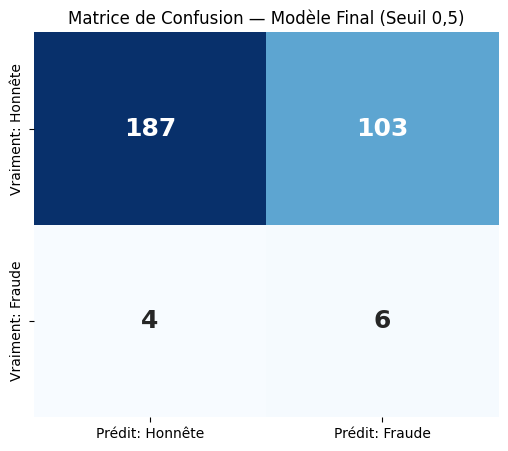

In [11]:
cm = confusion_matrix(Y_test, Y_pred_final)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 18, "weight": "bold"},
            xticklabels=['Prédit: Honnête', 'Prédit: Fraude'],
            yticklabels=['Vraiment: Honnête', 'Vraiment: Fraude'])
plt.title("Matrice de Confusion — Modèle Final (Seuil 0,5)")
plt.show()

# Étape 11 : Optimisation du seuil de décision
Le seuil par défaut (0,5) n'est pas optimal — comparaison ciblée entre
deux seuils via un graphique en barres, plus lisible qu'une courbe
Precision-Recall sur un aussi petit nombre de cas positifs.

Seuil 0.3 : Precision=0.053, Recall=0.800, F1=0.100, Faux Positifs=142
Seuil 0.5 : Precision=0.055, Recall=0.600, F1=0.101, Faux Positifs=103
Seuil 0.7 : Precision=0.102, Recall=0.500, F1=0.169, Faux Positifs=44
Seuil 0.9 : Precision=0.000, Recall=0.000, F1=0.000, Faux Positifs=0


/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


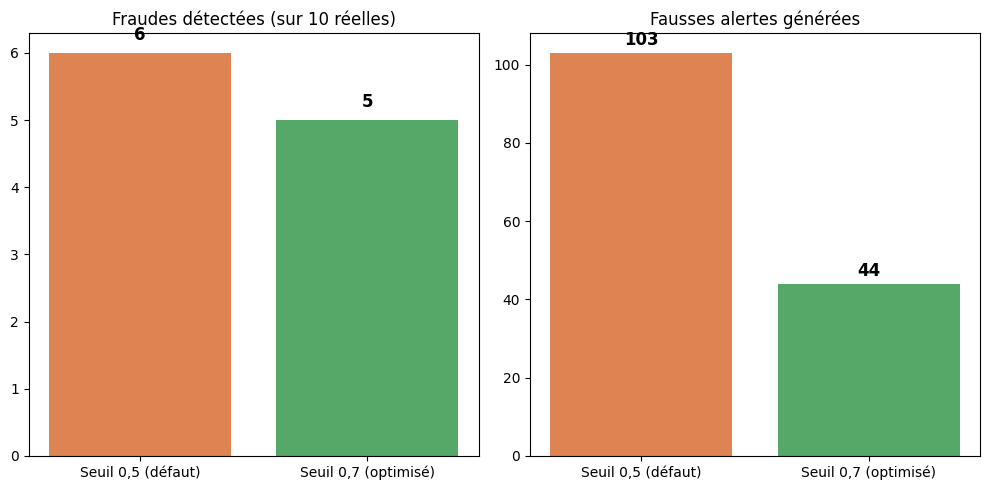

In [ ]:
Y_proba = model_final.predict_proba(X_test_r_proc)[:, 1]

resultats_seuils = {}
for seuil_test in [0.3, 0.5, 0.7, 0.9]:
    pred = (Y_proba >= seuil_test).astype(int)
    p = precision_score(Y_test, pred, zero_division=0)
    r = recall_score(Y_test, pred, zero_division=0)
    f1 = f1_score(Y_test, pred, zero_division=0)
    cm_test = confusion_matrix(Y_test, pred)
    resultats_seuils[seuil_test] = {"precision": p, "recall": r, "f1": f1, "faux_positifs": cm_test[0, 1], "vrais_positifs": cm_test[1, 1]} 
    print(f"Seuil {seuil_test} : Precision={p:.3f}, Recall={r:.3f}, F1={f1:.3f}, Faux Positifs={cm_test[0, 1]}")

# Comparaison visuelle : seuil par défaut (0.5) vs seuil optimisé (0.7)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
colors = ['#DD8452', '#55A868']
seuils_labels = ['Seuil 0,5 (défaut)', 'Seuil 0,7 (optimisé)']

# Les chiffres viennent des résultats calculés plus haut (pas écrits à la main)
fraudes_detectees = [resultats_seuils[0.5]["vrais_positifs"], resultats_seuils[0.7]["vrais_positifs"]]
fausses_alertes = [resultats_seuils[0.5]["faux_positifs"], resultats_seuils[0.7]["faux_positifs"]]

axes[0].bar(seuils_labels, fraudes_detectees, color=colors)
axes[0].set_title("Fraudes détectées (sur 10 réelles)")
for i, v in enumerate(fraudes_detectees):
    axes[0].text(i, v + 0.2, str(v), ha='center', fontweight='bold', fontsize=12)

axes[1].bar(seuils_labels, fausses_alertes, color=colors)
axes[1].set_title("Fausses alertes générées")
for i, v in enumerate(fausses_alertes):
    axes[1].text(i, v + 2, str(v), ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

# Étape 12 : Interprétation des coefficients (explicabilité réglementaire)
Traduction des coefficients du modèle en facteurs de risque
compréhensibles.

In [13]:
import numpy as np
noms = prep_reduit.get_feature_names_out()
coefs = model_final.coef_[0]
odds_ratios = np.exp(coefs)
df_coefs = pd.DataFrame({'Variable': noms, 'Coefficient': coefs, 'Odds_Ratio': odds_ratios}).sort_values('Coefficient', ascending=False)
print(df_coefs.to_string(index=False))

                                            Variable  Coefficient  Odds_Ratio
                      cat__customer_category_Workers     1.126813    3.085807
                               cat__customer_group_B     0.596215    1.815236
                               cat__customer_group_E     0.498876    1.646869
                                   num__customer_age     0.493756    1.638458
                               cat__customer_group_F     0.461527    1.586495
cat__customer_category_Higher managerial occupations     0.042963    1.043899
                               cat__customer_group_D    -0.034224    0.966355
     cat__customer_category_Intermediate occupations    -0.268883    0.764233
                          num__policies_last_3_years    -0.308675    0.734420
                         num__contract_duration_days    -0.430736    0.650031
          cat__customer_category_Own account workers    -0.985840    0.373125
                               cat__customer_group_C    -1.31488

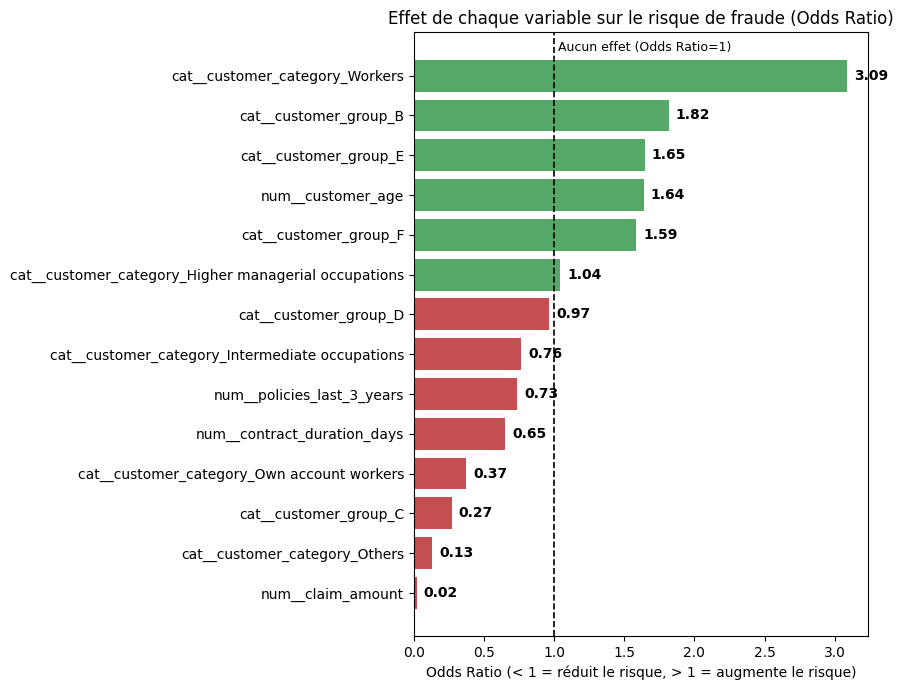

In [14]:
colors = ['#C44E52' if x < 1 else '#55A868' for x in df_coefs.sort_values('Odds_Ratio')['Odds_Ratio']]
df_coefs_tri = df_coefs.sort_values('Odds_Ratio', ascending=True)

plt.figure(figsize=(9, 7))
bars = plt.barh(df_coefs_tri['Variable'], df_coefs_tri['Odds_Ratio'], color=colors)
plt.axvline(x=1, color='black', linestyle='--', linewidth=1.2)
plt.text(1, len(df_coefs_tri) - 0.3, ' Aucun effet (Odds Ratio=1)', fontsize=9, va='center')
plt.title("Effet de chaque variable sur le risque de fraude (Odds Ratio)")
plt.xlabel("Odds Ratio (< 1 = réduit le risque, > 1 = augmente le risque)")

for bar, val in zip(bars, df_coefs_tri['Odds_Ratio']):
    plt.text(val + 0.05, bar.get_y() + bar.get_height() / 2, f"{val:.2f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Étape 13 : Déploiement opérationnel — Scoring de newclaims.csv
Application du modèle final aux nouveaux sinistres, sans étiquette
connue — le vrai test de mise en production.

In [15]:
newclaims_merged = newclaims.merge(contracts_clean, on='contract_id') \
    .merge(customers_clean, on='customer_id') \
                             .merge(departements_clean, on='code_dep')

X_new_r = newclaims_merged[features_reduits + cat_reduits]
X_new_r_proc = prep_reduit.transform(X_new_r)
newclaims_merged['score_risque'] = model_final.predict_proba(X_new_r_proc)[:, 1]

top5 = newclaims_merged.sort_values('score_risque', ascending=False)[['claim_amount', 'customer_age', 'score_risque']].head(5)
print(top5)

      claim_amount  customer_age  score_risque
1380         70.97            73      0.958031
1223        114.55            84      0.941611
1376          0.00            53      0.934049
1222        220.67            84      0.934008
778           0.00            71      0.921255


/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mme.nouko/miniconda3/lib/python3.13/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


# Étape 14 : Conclusion et limites

## Ce que j'ai fait
J'ai appris à un modèle à repérer les sinistres suspects (les fraudes). Dans mes données (1 497 dossiers), seulement **3 %** sont des fraudes : c'est très rare, donc difficile à repérer. Mon jeu de test contient 300 dossiers, dont **10 fraudes**.

## Mes résultats
Le **seuil**, c'est le niveau de certitude à partir duquel le modèle dit « fraude ». Plus on le monte, moins il fait de fausses alertes, mais plus il rate de fraudes.

| Seuil | Fraudes trouvées (sur 10) | Fausses alertes (dossiers normaux signalés à tort) | Alertes qui sont vraiment des fraudes |
|---|---|---|---|
| 0,5 (par défaut) | 6 | 103 | 5,5 % |
| 0,7 | 5 | 44 | 10,2 % |

## Ce que ça veut dire
- Avec le seuil de 0,7, le modèle signale 49 dossiers et trouve 5 fraudes sur 10. En choisissant 49 dossiers au hasard, on en trouverait environ 1 ou 2. Le modèle fait donc **mieux que le hasard**.
- La règle simple « un gros montant est suspect » ne trouve **aucune** fraude.
- J'ai aussi testé des modèles plus puissants. XGBoost a une meilleure note globale (F1 de 0,33 contre 0,10 : le F1 est une note qui mélange les fraudes trouvées et les alertes justes). J'ai gardé la régression logistique car on peut **expliquer** pourquoi elle donne un risque élevé, et parce qu'elle trouve bien les fraudes.

## Mes limites
- Il y a seulement **10 fraudes** dans le test : c'est trop peu pour être sûr. Une fraude de plus ou de moins change le résultat de 10 points.
- J'ai choisi le seuil de 0,7 **en regardant le jeu de test** : le résultat est un peu trop beau.
- Il y a beaucoup de **fausses alertes** : chacune devrait être vérifiée par une personne.
- Les données sont **fictives** (Kaggle). Le modèle trouve que les petits montants sont plus suspects, ce qui n'aurait pas de sens dans la vraie vie : c'est une particularité de ces données.
- Je n'ai fait **qu'une seule séparation** entre apprentissage et test.
- Des messages d'avertissement (`RuntimeWarning`) apparaissent pendant l'entraînement : ce sont des calculs numériques un peu instables. Les résultats sont les mêmes à chaque lancement.
